**Суркова Татьяна**

## Домашнее задание 5

Нужна небольшая модель учёта банковских счетов: расчётный и сберегательный счёт. Система должна вести историю операций, валидировать входные данные, отличать успешные операции от отклонённых и давать простую аналитику.

Решение оформите в объектно-ориентированном стиле. Опирайтесь на материалы тем 1–5. Конкретную структуру классов, имена методов и способ хранения данных выбираете вы - важно, чтобы поведение системы соответствовало правилам ниже и чтобы демонстрация в ноутбуке это подтверждала.

**Задание 1**

Реализуйте модель банковского счёта, которая не только меняет баланс, но и ведёт детальную историю действий.


**Этап 1**

**Правила**

- Счёт открывается с именем владельца и начальным балансом. Начальный баланс не может быть отрицательным (по умолчанию - 0).


- Номер счёта формируется автоматически в формате ACC-XXXX, где XXXX - порядковый номер. Счётчик номеров начинается с 1000. Номера счетов должны быть уникальными.


- Поддерживаются операции пополнения и снятия:

1. Сумма операции должна быть положительной.

2. Некорректная сумма приводит к исключению.

3. При успехе баланс обновляется, в историю добавляется запись со статусом успешной операции.

4. Если средств недостаточно, баланс не меняется, но попытка обязательно фиксируется в истории со статусом неуспешной операции.


- Каждая запись истории — структурированные данные. Минимум полей: тип операции (deposit / withdraw), сумма, дата и время, баланс после операции, статус (success / fail). Для даты и времени используйте модуль datetime.

- Должна быть возможность узнать текущий баланс и получить историю операций в удобном для чтения виде.

**Этап 2**

По истории операций постройте линейный график изменения баланса во времени (ось X - время операции, ось Y - баланс после операции). У графика должны быть заголовок и подписи осей.

In [2]:
# ЭТАП 1
import json
import re
import time
from datetime import datetime

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


class Account:
    # порядковый счётчик номеров счетов, начинается с 1000
    _account_counter = 1000

    _transfer_counter = 1
    # тип счёта: у наследников переопределяется
    account_type = "base"

    def __init__(self, account_holder, balance=0):
        self._validate_holder(account_holder)
        self._validate_initial_balance(balance)

        self.holder = account_holder
        self._balance = balance

        self.account_number = f"ACC-{Account._account_counter}"
        Account._account_counter += 1

        self.operations_history = []

        # Запись начальной операции в историю
        if balance > 0:
            self._add_new_operation('initial', balance, balance, 'success')

    # валидации
    @staticmethod
    def _validate_holder(name):
        """Валидация имени владельца счёта"""
        if not isinstance(name, str):
            raise ValueError("Имя владельца должно быть строкой")
        word = r'([A-Z][a-z]+|[А-ЯЁ][а-яё]+)'
        if not re.fullmatch(word + ' ' + word, name):
            raise ValueError("Имя владельца должно быть в формате "
                             "'Имя Фамилия' с заглавных букв")

    @staticmethod
    def _is_number(value):
        """Проверка на число, но не bool"""
        return isinstance(value, (int, float)) and not isinstance(value, bool)

    def _validate_initial_balance(self, balance):
        """Проверка стартового баланса"""
        if not self._is_number(balance):
            raise ValueError("Начальный баланс должен быть числом")
        if balance < 0:
            raise ValueError("Начальный баланс не может быть отрицательным")

    def _validate_amount(self, amount):
        """Проверка суммы операции"""
        if not self._is_number(amount):
            raise ValueError("Сумма операции должна быть числом")
        if amount <= 0:
            raise ValueError("Сумма операции должна быть положительной")


    def _add_new_operation(self, operation_type, amount, balance_after, status,
                           transfer_id=None, counterparty=None):
        """Запись новой операции в историю операций"""
        new_operation = {
            'operation': operation_type,
            'amount': amount,
            'date_time': datetime.now(),
            'balance_after': balance_after,
            'status': status,
            # общий номер перевода у обоих счетов (доп. задание)
            'transfer_id': transfer_id,
            # номер счёта второй стороны перевода (доп. задание)
            'counterparty': counterparty
        }
        self.operations_history.append(new_operation)

    def _can_withdraw(self, amount):
        return amount <= self._balance

    # операции
    def deposit(self, amount):
        """Операция пополнения счета"""
        try:
            self._validate_amount(amount)
            self._balance += amount
            self._add_new_operation('deposit', amount, self._balance,
                                    'success')
            return 'success'
        except ValueError as e:
            self._add_new_operation('deposit', amount, self._balance, 'fail')
            raise e

    def withdraw(self, amount):
        """Операция снятия со счета"""
        try:
            self._validate_amount(amount)
            if self._can_withdraw(amount):
                self._balance -= amount
                self._add_new_operation('withdraw', amount, self._balance,
                                        'success')
                return 'success'
            else:
                self._add_new_operation('withdraw', amount, self._balance,
                                        'fail')
                return 'fail'
        except ValueError as e:
            self._add_new_operation('withdraw', amount, self._balance, 'fail')
            raise e

    def current_balance(self):
        """Получение текущего баланса"""
        return self._balance

    def get_operations_history(self):
        """Получить историю операций в удобном для чтения виде - таблице"""
        if not self.operations_history:
            return "История операций пуста"
        df = pd.DataFrame(self.operations_history)

        # время без миллисекунд
        df['date_time'] = df['date_time'].dt.strftime('%d.%m.%Y %H:%M:%S')

        # суммы с пробелом между разрядами: 1700 -> 1 700
        def fmt(x):
            if isinstance(x, (int, float)):
                return f"{x:,}".replace(",", " ")
            return str(x)

        df['amount'] = df['amount'].map(fmt)
        df['balance_after'] = df['balance_after'].map(fmt)

        return df

    def latest_large_operations(self, n=5, min_amount=1000):
        """Последние N успешных операций на сумму не меньше min_amount"""
        if n <= 0:
            return []
        # сначала проверяем статус: у неуспешных сумма может быть строкой
        large = [op for op in self.operations_history
                 if op['status'] == 'success' and op['amount'] >= min_amount]
        return large[-n:]

    # ЭТАП 2 - ВИЗУАЛИЗАЦИЯ
    def plot_balance_history(self):
        """Линейный график изменения баланса во времени"""
        df = pd.DataFrame(self.operations_history)

        if df.empty:
            print("Нет операций для построения графика")
            return

        # берем только успешные операции: неудачные баланс не меняют
        df = df[df['status'] == 'success']

        if df.empty:
            print("Нет успешных операций для построения графика")
            return

        ax = df.plot(
            x='date_time',
            y='balance_after',
            kind='line',
            marker='o',
            figsize=(7, 4),
            grid=True,
            legend=False,
            title=(f"Изменение баланса счета {self.account_number} "
                   f"({self.holder})")
        )
        ax.set_xlabel("Дата и время операции")
        ax.set_ylabel("Баланс")

        plt.gcf().autofmt_xdate()
        plt.tight_layout()
        plt.show()

    # дополнительное задание
    def transfer(self, target, amount):
        """Перевод суммы на счет target. Возвращает 'success' или 'fail'"""
        # проверка получателя
        if not isinstance(target, Account):
            raise ValueError("Получатель должен быть счётом")
        if target is self:
            raise ValueError("Нельзя переводить деньги на тот же счёт")

        # общий номер перевода, он одинаковый в историях обоих счетов
        transfer_id = f"TRF-{Account._transfer_counter}"
        Account._transfer_counter += 1

        # проверка суммы, фиксируется в истории
        try:
            self._validate_amount(amount)
        except ValueError:
            self._add_new_operation('transfer_out', amount, self._balance,
                                    'fail', transfer_id,
                                    target.account_number)
            raise

        # проверка на ограничение сбер.счета и на достаточность денег
        if not self._can_withdraw(amount):
            self._add_new_operation('transfer_out', amount, self._balance,
                                    'fail', transfer_id,
                                    target.account_number)
            return 'fail'

        # при успехе списываем у отправителя и зачисляем получателю,
        # в историях обоих счетов записи с одним transfer_id
        self._balance -= amount
        self._add_new_operation('transfer_out', amount, self._balance,
                                'success', transfer_id,
                                target.account_number)
        target._balance += amount
        target._add_new_operation('transfer_in', amount, target._balance,
                                  'success', transfer_id,
                                  self.account_number)
        return 'success'

Создан счёт: ACC-1000 | владелец: Иван Петров
Начальный баланс: 1000
Второй счёт: ACC-1001 | владелец: Иван Иванов
Начальный баланс: 0
Снятие 10 000: fail
Ошибка при пополнении на -50: Сумма операции должна быть положительной
Ошибка при пополнении на 0: Сумма операции должна быть положительной
Ошибка при пополнении на 'сто': Сумма операции должна быть числом
Ошибка создания счёта: Начальный баланс не может быть отрицательным
Текущий баланс: 1700
История операций:


,operation,amount,date_time,balance_after,status,transfer_id,counterparty
0,initial,1 000,22.10.2026 23:36:24,1 000,success,None,None
1,deposit,500,22.10.2026 23:36:25,1 500,success,None,None
2,withdraw,300,22.10.2026 23:36:25,1 200,success,None,None
3,deposit,1 200,22.10.2026 23:36:26,2 400,success,None,None
4,withdraw,700,22.10.2026 23:36:26,1 700,success,None,None
5,withdraw,10 000,22.10.2026 23:36:26,1 700,fail,None,None
6,deposit,-50,22.10.2026 23:36:26,1 700,fail,None,None
7,deposit,0,22.10.2026 23:36:26,1 700,fail,None,None
8,deposit,сто,22.10.2026 23:36:26,1 700,fail,None,None


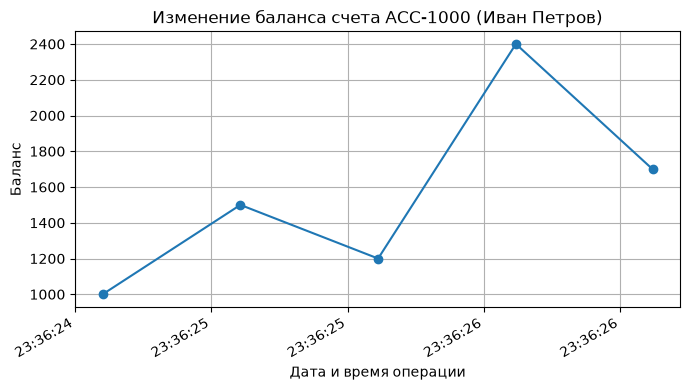

In [ ]:
# Демонстрация (задание 1)

pd.set_option('display.width', 200)

# Создание счёта
acc = Account("Иван Петров", 1000)
print("Создан счёт:", acc.account_number, "| владелец:", acc.holder)
print("Начальный баланс:", acc.current_balance())

# Номера уникальны и идут по порядку
acc2 = Account("Иван Иванов")
print("Второй счёт:", acc2.account_number, "| владелец:", acc2.holder)
print("Начальный баланс:", acc2.current_balance())

# Операции (паузы между ними добавлены, чтобы время на графике различалось)
time.sleep(0.5)
acc.deposit(500)
time.sleep(0.5)
acc.withdraw(300)
time.sleep(0.5)
acc.deposit(1200)
time.sleep(0.5)
acc.withdraw(700)

# Неуспешная попытка снятия (недостаточно средств)
result = acc.withdraw(10_000)
print(f"Снятие 10 000: {result}")

# Некорректные суммы отдают исключение,попытка попадает в историю
for bad_amount in (-50, 0, "сто"):
    try:
        acc.deposit(bad_amount)
    except ValueError as e:
        print(f"Ошибка при пополнении на {bad_amount!r}: {e}")

# Некорректные данные при создании счёта
try:
    Account("Тест Тестов", -100)
except ValueError as e:
    print("Ошибка создания счёта:", e)

# Баланс
print("Текущий баланс:", acc.current_balance())

# История
print("История операций:")
display(acc.get_operations_history())

# График
acc.plot_balance_history()

**Задание 2. Разные типы счетов и аналитика**

Расчётный и сберегательный счета должны отражать общее поведение учёта операций, но отличаться правилами.

**Правила**

- Расчётный счёт - базовые пополнение и снятие без дополнительных ограничений на долю снимаемой суммы.

- Сберегательный счёт: умеет начислять проценты на текущий остаток (ставку задаёт вызывающий код, например 7%); нельзя снять больше 50% текущего баланса; нарушающая правило попытка не меняет баланс и фиксируется в истории как неуспешная.

- У каждого типа счёта должен быть различимый тип (чтобы по объекту/данным было понятно, расчётный это счёт или сберегательный).

- Валидация имени владельца: формат «Имя Фамилия», слова с заглавной буквы, кириллица или латиница. Иначе - исключение. Для проверки используйте регулярные выражения.

- Аналитика по истории: возможность получить последние N крупных успешных операций (порог «крупности» и N задаёт вызывающий код).

**Дополнительное задание. Перевод между счетами**

Добавьте возможность перевода средств с одного счёта на другой:

- при успехе сумма списывается у отправителя и зачисляется получателю;
- если списание у отправителя невозможно (недостаточно средств или сработали ограничения сберегательного счёта), баланс получателя не меняется;
- в историях обоих счетов перевод должен быть различим (например, общий идентификатор перевода, связанные записи или иной явный признак - способ выбираете вы).

Этот пункт не обязателен, но без него сложно претендовать на верхнюю часть шкалы: он показывает, насколько согласовано поведение разных счетов и насколько аккуратно продуманы связанные операции.

In [4]:
class PaymentAccount(Account):
    """Расчётный счёт: без дополнительных ограничений"""
    account_type = "payment"

class SavingsAccount(Account):
    """Сберегательный счёт: проценты и лимит снятия 50% от баланса"""
    account_type = "savings"

    def _can_withdraw(self, amount):
        """Нельзя снять больше 50% текущего баланса"""
        return amount <= self._balance * 0.5

    def apply_interest(self, rate):
        """Начисление процентов на остаток"""
        if not self._is_number(rate) or rate <= 0:
            raise ValueError(
                "Процентная ставка должна быть положительным числом")

        interest_amount = round(self._balance * (rate / 100), 2)
        self._balance += interest_amount
        self._add_new_operation('interest', interest_amount, self._balance,
                                'success')
        return interest_amount

In [5]:
# Демонстрация (задание 2)

# создание расчетного и сберегательного счетов
payment = PaymentAccount("Мария Соколова", 10000)
savings = SavingsAccount("Олег Новиков", 50000)
for account in (payment, savings):
    print(f"{account.account_number} | тип: {account.account_type:<8} | "
          f"владелец: {account.holder} | баланс: {account.current_balance()}")

# начисление процентов
interest = savings.apply_interest(7)
print(f"Начислено: {interest}, баланс: {savings.current_balance()}")

# ограничение 50%
limit = savings.current_balance() * 0.5
print(f"Баланс: {savings.current_balance()}, максимум для снятия: {limit}")
status = savings.withdraw(30000)   # больше 50% отказ
print(f"Снятие 30 000: {status} (баланс: {savings.current_balance()})")
status = savings.withdraw(20000)   # в пределах 50% успех
print(f"Снятие 20 000: {status} (баланс: {savings.current_balance()})")

# последние крупные операции
for op in savings.latest_large_operations(n=2, min_amount=10000):
    print(f"{op['date_time']:%H:%M:%S} | {op['operation']:<9} | "
          f"{op['amount']}")

# валидация имени владельца
for bad_name in ("иван петров", "Иван", "Иван123 Петров", 123):
    try:
        PaymentAccount(bad_name, 100)
    except ValueError as e:
        print(f"Имя {bad_name!r} -> ошибка: {e}")

# некорректный процент
try:
    savings.apply_interest(-3)
except ValueError as e:
    print(f"apply_interest(-3) -> ошибка: {e}")

# переводы
print(f"До переводов: расчётный {payment.current_balance()}, "
      f"сберегательный {savings.current_balance()}")
# успешный перевод
status = payment.transfer(savings, 2000)
print(f"Расчётный -> сберегательный, 2 000: {status}")
print(f"После перевода: расчётный {payment.current_balance()}, "
      f"сберегательный {savings.current_balance()}")
# неуспешный перевод
status = payment.transfer(savings, 100000)
print(f"\nРасчётный -> сберегательный, 100 000: {status} (не хватает средств)")

# при неудачном переводе баланс получателя не меняется
# (в том числе когда сработало ограничение 50% у сберегательного счёта)
before = payment.current_balance()
status = savings.transfer(payment, 30000)  # больше 50% баланса сбер. счёта
print(f"\nСберегательный -> расчётный, 30 000: {status} (лимит 50%)")
print("Баланс расчётного не изменился:", payment.current_balance() == before)

for account in (payment, savings):
    history = account.get_operations_history()
    print(f"\nПереводы в истории {account.account_number} "
          f"({account.account_type}):")
    display(history[history['transfer_id'].notna()])

ACC-1002 | тип: payment  | владелец: Мария Соколова | баланс: 10000
ACC-1003 | тип: savings  | владелец: Олег Новиков | баланс: 50000
Начислено: 3500.0, баланс: 53500.0
Баланс: 53500.0, максимум для снятия: 26750.0
Снятие 30 000: fail (баланс: 53500.0)
Снятие 20 000: success (баланс: 33500.0)
23:36:26 | initial   | 50000
23:36:26 | withdraw  | 20000
Имя 'иван петров' -> ошибка: Имя владельца должно быть в формате 'Имя Фамилия' с заглавных букв
Имя 'Иван' -> ошибка: Имя владельца должно быть в формате 'Имя Фамилия' с заглавных букв
Имя 'Иван123 Петров' -> ошибка: Имя владельца должно быть в формате 'Имя Фамилия' с заглавных букв
Имя 123 -> ошибка: Имя владельца должно быть строкой
apply_interest(-3) -> ошибка: Процентная ставка должна быть положительным числом
До переводов: расчётный 10000, сберегательный 33500.0
Расчётный -> сберегательный, 2 000: success
После перевода: расчётный 8000, сберегательный 35500.0

Расчётный -> сберегательный, 100 000: fail (не хватает средств)

Сберегатель

,operation,amount,date_time,balance_after,status,transfer_id,counterparty
1,transfer_out,2 000,22.10.2026 23:36:26,8 000,success,TRF-1,ACC-1003
2,transfer_out,100 000,22.10.2026 23:36:26,8 000,fail,TRF-2,ACC-1003



Переводы в истории ACC-1003 (savings):


,operation,amount,date_time,balance_after,status,transfer_id,counterparty
4,transfer_in,2 000.0,22.10.2026 23:36:26,35 500.0,success,TRF-1,ACC-1002
5,transfer_out,30 000.0,22.10.2026 23:36:26,35 500.0,fail,TRF-3,ACC-1002


**Задание 3. Загрузка «грязных» данных**

Перед началом работы загрузите из личного кабинета файлы transactions_dirty.csv и transactions_dirty.json.

Файл общий для нескольких счетов: нужно загружать в конкретный счёт только его операции (фильтрация по номеру счёта / типу - по данным файла).

Правила

- Реализуйте загрузку истории из CSV и\или из JSON.

- Перед записью в историю отбрасывайте невалидные строки: опечатки в типе операции, пустые или отрицательные суммы, некорректные даты, некорректный статус и т.п.

- Для сберегательного счёта допустимы типы операций deposit, withdraw, interest; для расчётного - только deposit и withdraw. Операции, недопустимые для типа счёта, невалидны.

- После успешной загрузки валидных операций баланс счёта должен соответствовать последовательности принятых операций.
Демонстрация

**Дополнительное задание. Отчёт об отбраковке**

Помимо «молчаливого» отбрасывания мусора сформируйте явный результат очистки:

- сколько строк принято,

- сколько отклонено,

- почему отклонена каждая (или группа) строк - битая дата, пустая сумма, опечатка в типе (diposit), interest на расчётном счёте, неверный статус и т.д.

Формат отчёта на ваш выбор (список, датафрейм, печать сводки) - главное, чтобы его можно было показать в ноутбуке и по нему было понятно, что произошло с данными.

Этот пункт не обязателен, но без него сложно претендовать на верхнюю часть шкалы: он показывает зрелость работы с внешними данными, а не только «файл как-то прочитался».


In [6]:
# задание 3

class TransactionLoader:
    """Загрузка операций из CSV/JSON в уже созданный счёт.
    Работает с любым счётом (расчётным и сберегательным): допустимые
    операции берутся по типу счёта (account.account_type).
    """
    # какие операции допустимы для каждого типа счёта
    allowed = {
        'payment': ('deposit', 'withdraw'),
        'savings': ('deposit', 'withdraw', 'interest')
    }
    # форматы дат, которые встречаются в файлах
    date_formats = ("%Y-%m-%d %H:%M:%S", "%d/%m/%Y %H:%M")

    def __init__(self, account, file_account):
        if account.account_type not in self.allowed:
            raise ValueError("Неизвестный тип счёта")
        self.account = account
        # номер этого счёта в файле (у объекта номер другой: ACC-10xx)
        self.file_account = file_account
        self.report = None

    def load(self, filename):
        """Читает файл, чистит строки, записывает валидные в счёт"""
        if filename.endswith('.csv'):
            df = pd.read_csv(filename)
        elif filename.endswith('.json'):
            with open(filename, 'r', encoding='utf-8') as f:
                df = pd.DataFrame(json.load(f))
        else:
            raise ValueError("Поддерживаются только CSV и JSON файлы")

        # файл общий: оставляем только строки нашего счёта
        df = df[df['account_number'] == self.file_account].copy()
        # всё, что не число (например, пустая сумма), станет NaN
        df['amount'] = pd.to_numeric(df['amount'], errors='coerce')

        self._clean_and_load(df)
        return self.report

    def _parse_date(self, value):
        """Дата из строки в datetime, при ошибке возвращает None"""
        if not isinstance(value, str):
            return None
        for date_format in self.date_formats:
            try:
                return datetime.strptime(value, date_format)
            except ValueError:
                continue
        return None

    def _row_error(self, row):
        """Проверка строки. Возвращает причину отказа или None"""
        known = ('deposit', 'withdraw', 'interest')
        operation = row['operation']

        if pd.isna(operation):
            return "пустой тип операции"
        if operation not in known:
            return "опечатка в типе операции"
        if operation not in self.allowed[self.account.account_type]:
            return (f"{operation} недопустим для счёта типа "
                    f"{self.account.account_type}")
        if pd.isna(row['amount']):
            return "пустая сумма"
        if row['amount'] <= 0:
            return "отрицательная сумма"
        if self._parse_date(row['date']) is None:
            return "некорректная дата"
        if row['status'] not in ('success', 'fail'):
            return "неверный статус"
        return None

    def _apply(self, row):
        """Записывает операцию в историю счёта и меняет баланс.
        Возвращает False, если для снятия не хватает средств.
        """
        acc = self.account
        amount = float(row['amount'])
        operation = row['operation']

        # неуспешная операция попадает в историю, но баланс не меняет
        if row['status'] == 'success':
            if operation == 'withdraw':
                if amount > acc.current_balance():
                    return False
                acc._balance = round(acc.current_balance() - amount, 2)
            else:  # deposit и interest увеличивают баланс
                acc._balance = round(acc.current_balance() + amount, 2)

        # запись в том же формате, что и у обычных операций счёта
        acc.operations_history.append({
            'operation': operation,
            'amount': amount,
            'date_time': self._parse_date(row['date']),
            'balance_after': acc.current_balance(),
            'status': row['status'],
            'transfer_id': None,
            'counterparty': None
        })
        return True

    def _clean_and_load(self, df):
        """Проверка всех строк, запись валидных, сбор отчёта"""
        results = {}     # индекс строки отдаст 'принята' или причину отказа
        valid_rows = []  # строки, прошедшие проверки
        seen = set()     # для поиска дубликатов

        for index, row in df.iterrows():
            reason = self._row_error(row)
            row_key = tuple(row.astype(str))
            if reason is None and row_key in seen:
                reason = "дубликат строки"

            if reason is None:
                seen.add(row_key)
                valid_rows.append((index, row))
            else:
                results[index] = reason

        # операции идут по порядку дат (сортировка стабильная)
        valid_rows.sort(key=lambda item: self._parse_date(item[1]['date']))

        for index, row in valid_rows:
            if self._apply(row):
                results[index] = "принята"
            else:
                results[index] = "недостаточно средств для снятия"

        self.report = df[['date', 'operation', 'amount', 'status']].copy()
        self.report['result'] = pd.Series(results)

    def show_report(self, title):
        """Печатает сводку: сколько принято, сколько и почему отклонено"""
        report = self.report
        accepted = (report['result'] == 'принята').sum()
        rejected = report[report['result'] != 'принята']

        print(f"=== Отчёт об отбраковке: {title} ===")
        print(f"Строк этого счёта в файле: {len(report)}")
        print(f"Принято: {accepted}")
        print(f"Отклонено: {len(rejected)}")

        if not rejected.empty:
            reasons = (rejected['result'].value_counts()
                       .rename_axis('причина').reset_index(name='строк'))
            print("Причины отказа:")
            display(reasons)
            print("Отклонённые строки (индекс - номер строки в данных с 0):")
            display(rejected)

In [7]:
# Демонстрация (задание 3)

csv_payment = PaymentAccount("Анна Смирнова", 1200)
csv_savings = SavingsAccount("Пётр Кузнецов", 1500)

loader_payment = TransactionLoader(csv_payment, 'ACC-100001')
loader_savings = TransactionLoader(csv_savings, 'ACC-100002')
loader_payment.load('transactions_dirty.csv')
loader_savings.load('transactions_dirty.csv')

# обновлённый баланс и фрагмент истории (первые 8 операций)
print("Расчётный счёт, баланс:", csv_payment.current_balance())
display(csv_payment.get_operations_history().head(8))
print("\nСберегательный счёт, баланс:", csv_savings.current_balance())
display(csv_savings.get_operations_history().head(8))

# отчёты об отбраковке
print()
loader_payment.show_report("расчётный счёт ACC-100001")
print()
loader_savings.show_report("сберегательный счёт ACC-100002")

# то же самое из JSON (результат совпадает с CSV)
json_payment = PaymentAccount("Анна Смирнова", 1200)
TransactionLoader(json_payment, 'ACC-100001').load('transactions_dirty.json')
print("Баланс расчётного из JSON:", json_payment.current_balance(),
      "| из CSV:", csv_payment.current_balance())

Расчётный счёт, баланс: 4864.0


,operation,amount,date_time,balance_after,status,transfer_id,counterparty
0,initial,1 200.0,22.10.2026 23:36:26,1 200.0,success,None,None
1,deposit,921.0,27.09.2025 22:17:26,2 121.0,success,None,None
2,deposit,607.0,27.09.2025 22:17:26,2 728.0,success,None,None
3,deposit,129.0,28.09.2025 22:17:00,2 857.0,success,None,None
4,deposit,488.0,28.09.2025 22:17:26,3 345.0,success,None,None
5,deposit,880.0,29.09.2025 22:17:26,4 225.0,success,None,None
6,withdraw,352.0,01.10.2025 22:17:26,3 873.0,success,None,None
7,withdraw,65.0,01.10.2025 22:17:26,3 808.0,success,None,None



Сберегательный счёт, баланс: 3991.24


,operation,amount,date_time,balance_after,status,transfer_id,counterparty
0,initial,1 500.0,22.10.2026 23:36:26,1 500.0,success,None,None
1,deposit,469.0,27.09.2025 22:17:26,1 969.0,success,None,None
2,withdraw,392.0,27.09.2025 22:17:26,1 577.0,success,None,None
3,deposit,317.0,28.09.2025 22:17:26,1 894.0,success,None,None
4,deposit,840.0,02.10.2025 22:17:26,2 734.0,success,None,None
5,interest,183.28,04.10.2025 22:17:00,2 917.28,success,None,None
6,interest,192.44,06.10.2025 22:17:26,3 109.72,success,None,None
7,deposit,426.0,08.10.2025 22:17:26,3 535.72,success,None,None



=== Отчёт об отбраковке: расчётный счёт ACC-100001 ===
Строк этого счёта в файле: 26
Принято: 17
Отклонено: 9
Причины отказа:


...


=== Отчёт об отбраковке: сберегательный счёт ACC-100002 ===
Строк этого счёта в файле: 27
Принято: 18
Отклонено: 9
Причины отказа:


,причина,строк
0,отрицательная сумма,2
1,опечатка в типе операции,2
2,неверный статус,2
3,некорректная дата,1
4,пустая сумма,1
5,дубликат строки,1


Отклонённые строки (индекс - номер строки в данных с 0):


,date,operation,amount,status,result
28,2023-22-32 12:00:00,deposit,797.0,success,некорректная дата
29,2025-09-30 22:17:26,interest,NaN,success,пустая сумма
33,2025-10-08 22:17:26,deposit,-136.0,success,отрицательная сумма
37,2025-10-09 22:17:26,diposit,432.0,success,опечатка в типе операции
44,2025-10-16 22:17:26,deposit,-872.0,success,отрицательная сумма
46,2025-10-19 22:17:26,withdraw,300.0,succes,неверный статус
48,2025-10-22 22:17:26,wdraw,457.0,success,опечатка в типе операции
100,09/10/2025 22:17,deposit,638.0,success,дубликат строки
103,2025-10-19 22:17:26,withdraw,300.0,succes,неверный статус


Баланс расчётного из JSON: 4864.0 | из CSV: 4864.0
